<a href="https://colab.research.google.com/github/udlbook/udlbook/blob/main/Notebooks/Chap09/9_2_Implicit_Regularization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Make function smoother 


## Explicit Regularization

Consider fitting a model $f[x,\phi]$ with parameters $\phi$ using a training set $\{x_i,y_i\}$ of input/output pairs. We seek the parameters $\phi$ that minimize the loss function $L[\phi]$ :

$$
\begin{align}
\hat{\phi} &= \arg\min_\phi L[\phi] \\
\hat{\phi} &= \arg\min_\phi \left[ \sum_i \ell[x_i, y_i] \right]
\end{align}
$$

where the individual terms $\ell_i[x_i,y_i]$ measure the mismatch between the network predictions $f[x_i,\phi]$ and output targets $y_i$ for each training pair. To bias this minimization toward certain solutions, we include an additional term:

$$
\hat{\phi} = \arg\min_\phi \left[ \sum_i \ell[x_i, y_i] + \lambda g[\phi] \right]
$$

where $g[\phi]$ is a function that returns a scalar which takes larger values when the parameters are less preferred. 

The term $\lambda$ is a positive scalar that controls the relative contribution of the original loss function and the regularization term. The minima of the regularized loss function usually differ from those in the original, so the training procedure converges to different parameter values.

<img src="assets/Chap09/RegExplicitTheory.svg" width="100%">

Explicit regularization. a) Loss function for Gabor model. Cyan circles represent local minima. Gray circle represents the global
minimum. b) The regularization term favors parameters close to the center of the
plot by adding an increasing penalty as we move away from this point. c) The
final loss function is the sum of the original loss function plus the regularization
term. This surface has fewer local minima, and the global minimum has moved
to a different position (arrow shows change).

---

<img src="assets/Chap09/RegExplicitPractice.svg" width="100%" style="filter:invert(1)">

L2 regularization in simplified network with 14 hidden units (see fig-
ure 8.4). a–f) Fitted functions as we increase the regularization coeﬀicient λ. The
black curve is the true function, the orange circles are the noisy training data,
and the cyan curve is the fitted model. For small λ(panels a–b), the fitted func-
tion passes exactly through the data points. For intermediate λ(panels c–d), the
function is smoother and more similar to the ground truth. For large λ (panels
e–f), the regularization term overpowers the likelihood term, so the fitted function
is too smooth and the overall fit is worse.

---
<!-- 
### Probabilistic interpretation 

Regularization can be viewed from a probabilistic perspective. Section 5.1 shows how
loss functions are constructed from the maximum likelihood criterion:

$$
\hat{\phi} = \arg\max_\phi \prod_{i=1}^{I} p(y_i | x_i, \phi)
$$

The regularization term can be considered as a prior Pr(ϕ) that represents knowledge
about the parameters before we observe the data and we now have the maximum a
posteriori or MAP criterion:

$$
\hat{\phi} = \arg\max_\phi \left[ \prod_{i=1}^{I} p(y_i | x_i, \phi) \cdot \text{Pr}(\phi) \right]
$$

Moving back to the negative log-likelihood loss funcion by taking the log and multiplying
by minus one, we see that λ·g[ϕ] =−log[Pr(ϕ)]. -->


### L2 Regularization

This discussion has sidestepped the question of which solutions the regularization term
should penalize (or equivalently that the prior should favor). Since neural networks are
used in an extremely broad range of applications, these can only be very generic pref-
erences. The most commonly used regularization term is the L2 norm, which penalizes
the sum of the squares of the parameter values:

$$
g[\phi] = \arg\min_\phi \sum_{i=1}^{I} \ell_i[x_i, y_i] + \lambda \sum_{j} \phi_j^2
$$

where j indexes the parameters. This is also referred to as Tikhonov regularization or
ridge regression, or (when applied to matrices) Frobenius norm regularization.

<mark>For neural networks, L2 regularization is usually applied to the weights but not
the biases and is hence referred to as a weight decay term</mark>. The effect is to encourage
smaller weights, so the output function is smoother. To see this, consider that the
output prediction is a weighted sum of the activations at the last hidden layer. If the
weights have a smaller magnitude, the output will vary less. The same logic applies to
the computation of the pre-activations at the last hidden layer and so on, progressing
backward through the network. In the limit, if we forced all the weights to be zero, the
network would produce a constant output determined by the final bias parameter.

Figure 9.2 shows the effect of fitting the simplified network from figure 8.4 with weight
decay and different values of the regularization coeﬀicient λ. When λ is small, it has
little effect. However, as λ increases, the fit to the data becomes less accurate, and the
function becomes smoother. This might improve the test performance for two reasons:

* If the network is overfitting, then adding the regularization term means that the
network must trade off slavish adherence to the data against the desire to be
smooth. One way to think about this is that the error due to variance reduces (the
model no longer needs to pass through every data point) at the cost of increased
bias (the model can only describe smooth functions).

* When the network is over-parameterized, some of the extra model capacity de-
scribes areas with no training data. Here, the regularization term will favor func-
tions that smoothly interpolate between the nearby points. This is reasonable
behavior in the absence of knowledge about the true function.

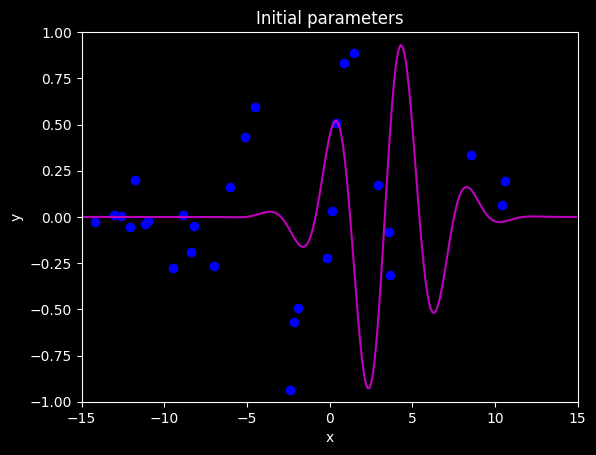

In [16]:
# import libraries
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm
from matplotlib.colors import ListedColormap

plt.style.use('dark_background')

# Let's create our training data 30 pairs {x_i, y_i}
# We'll try to fit the Gabor model to these data
data = np.array([[-1.920e+00,-1.422e+01,1.490e+00,-1.940e+00,-2.389e+00,-5.090e+00,
                 -8.861e+00,3.578e+00,-6.010e+00,-6.995e+00,3.634e+00,8.743e-01,
                 -1.096e+01,4.073e-01,-9.467e+00,8.560e+00,1.062e+01,-1.729e-01,
                  1.040e+01,-1.261e+01,1.574e-01,-1.304e+01,-2.156e+00,-1.210e+01,
                 -1.119e+01,2.902e+00,-8.220e+00,-1.179e+01,-8.391e+00,-4.505e+00],
                  [-1.051e+00,-2.482e-02,8.896e-01,-4.943e-01,-9.371e-01,4.306e-01,
                  9.577e-03,-7.944e-02 ,1.624e-01,-2.682e-01,-3.129e-01,8.303e-01,
                  -2.365e-02,5.098e-01,-2.777e-01,3.367e-01,1.927e-01,-2.222e-01,
                  6.352e-02,6.888e-03,3.224e-02,1.091e-02,-5.706e-01,-5.258e-02,
                  -3.666e-02,1.709e-01,-4.805e-02,2.008e-01,-1.904e-01,5.952e-01]])

# Gabor model definition
def model(phi,x):
  sin_component = np.sin(phi[0] + 0.06 * phi[1] * x)
  gauss_component = np.exp(-(phi[0] + 0.06 * phi[1] * x) * (phi[0] + 0.06 * phi[1] * x) / 32)
  y_pred= sin_component * gauss_component
  return y_pred

# Draw model
def draw_model(data,model,phi,title=None):
  x_model = np.arange(-15,15,0.1)
  y_model = model(phi,x_model)

  fix, ax = plt.subplots()
  ax.plot(data[0,:],data[1,:],'bo')
  ax.plot(x_model,y_model,'m-')
  ax.set_xlim([-15,15]);ax.set_ylim([-1,1])
  ax.set_xlabel('x'); ax.set_ylabel('y')
  if title is not None:
    ax.set_title(title)
  plt.show()
  
# Initialize the parameters and draw the model
phi = np.zeros((2,1))
phi[0] =  -5     # Horizontal offset
phi[1] =  25     # Frequency
draw_model(data,model,phi, "Initial parameters")

def compute_loss(data_x, data_y, model, phi):
  pred_y = model(phi, data_x)
  loss = np.sum((pred_y-data_y)*(pred_y-data_y))
  return loss

# Define pretty colormap
my_colormap_vals_hex =('2a0902', '2b0a03', '2c0b04', '2d0c05', '2e0c06', '2f0d07', '300d08', '310e09', '320f0a', '330f0b', '34100b', '35110c', '36110d', '37120e', '38120f', '39130f', '3a1410', '3b1411', '3c1511', '3d1612', '3e1613', '3f1713', '401714', '411814', '421915', '431915', '451a16', '461b16', '471b17', '481c17', '491d18', '4a1d18', '4b1e19', '4c1f19', '4d1f1a', '4e201b', '50211b', '51211c', '52221c', '53231d', '54231d', '55241e', '56251e', '57261f', '58261f', '592720', '5b2821', '5c2821', '5d2922', '5e2a22', '5f2b23', '602b23', '612c24', '622d25', '632e25', '652e26', '662f26', '673027', '683027', '693128', '6a3229', '6b3329', '6c342a', '6d342a', '6f352b', '70362c', '71372c', '72372d', '73382e', '74392e', '753a2f', '763a2f', '773b30', '783c31', '7a3d31', '7b3e32', '7c3e33', '7d3f33', '7e4034', '7f4134', '804235', '814236', '824336', '834437', '854538', '864638', '874739', '88473a', '89483a', '8a493b', '8b4a3c', '8c4b3c', '8d4c3d', '8e4c3e', '8f4d3f', '904e3f', '924f40', '935041', '945141', '955242', '965343', '975343', '985444', '995545', '9a5646', '9b5746', '9c5847', '9d5948', '9e5a49', '9f5a49', 'a05b4a', 'a15c4b', 'a35d4b', 'a45e4c', 'a55f4d', 'a6604e', 'a7614e', 'a8624f', 'a96350', 'aa6451', 'ab6552', 'ac6552', 'ad6653', 'ae6754', 'af6855', 'b06955', 'b16a56', 'b26b57', 'b36c58', 'b46d59', 'b56e59', 'b66f5a', 'b7705b', 'b8715c', 'b9725d', 'ba735d', 'bb745e', 'bc755f', 'bd7660', 'be7761', 'bf7862', 'c07962', 'c17a63', 'c27b64', 'c27c65', 'c37d66', 'c47e67', 'c57f68', 'c68068', 'c78169', 'c8826a', 'c9836b', 'ca846c', 'cb856d', 'cc866e', 'cd876f', 'ce886f', 'ce8970', 'cf8a71', 'd08b72', 'd18c73', 'd28d74', 'd38e75', 'd48f76', 'd59077', 'd59178', 'd69279', 'd7937a', 'd8957b', 'd9967b', 'da977c', 'da987d', 'db997e', 'dc9a7f', 'dd9b80', 'de9c81', 'de9d82', 'df9e83', 'e09f84', 'e1a185', 'e2a286', 'e2a387', 'e3a488', 'e4a589', 'e5a68a', 'e5a78b', 'e6a88c', 'e7aa8d', 'e7ab8e', 'e8ac8f', 'e9ad90', 'eaae91', 'eaaf92', 'ebb093', 'ecb295', 'ecb396', 'edb497', 'eeb598', 'eeb699', 'efb79a', 'efb99b', 'f0ba9c', 'f1bb9d', 'f1bc9e', 'f2bd9f', 'f2bfa1', 'f3c0a2', 'f3c1a3', 'f4c2a4', 'f5c3a5', 'f5c5a6', 'f6c6a7', 'f6c7a8', 'f7c8aa', 'f7c9ab', 'f8cbac', 'f8ccad', 'f8cdae', 'f9ceb0', 'f9d0b1', 'fad1b2', 'fad2b3', 'fbd3b4', 'fbd5b6', 'fbd6b7', 'fcd7b8', 'fcd8b9', 'fcdaba', 'fddbbc', 'fddcbd', 'fddebe', 'fddfbf', 'fee0c1', 'fee1c2', 'fee3c3', 'fee4c5', 'ffe5c6', 'ffe7c7', 'ffe8c9', 'ffe9ca', 'ffebcb', 'ffeccd', 'ffedce', 'ffefcf', 'fff0d1', 'fff2d2', 'fff3d3', 'fff4d5', 'fff6d6', 'fff7d8', 'fff8d9', 'fffada', 'fffbdc', 'fffcdd', 'fffedf', 'ffffe0')
my_colormap_vals_dec = np.array([int(element,base=16) for element in my_colormap_vals_hex])
r = np.floor(my_colormap_vals_dec/(256*256))
g = np.floor((my_colormap_vals_dec - r *256 *256)/256)
b = np.floor(my_colormap_vals_dec - r * 256 *256 - g * 256)
my_colormap = ListedColormap(np.vstack((r,g,b)).transpose()/255.0)

def draw_loss_function(compute_loss, data,  model, my_colormap, phi_iters = None):

  # Make grid of offset/frequency values to plot
  offsets_mesh, freqs_mesh = np.meshgrid(np.arange(-10,10.0,0.1), np.arange(2.5,22.5,0.1))
  loss_mesh = np.zeros_like(freqs_mesh)
  # Compute loss for every set of parameters
  for idslope, slope in np.ndenumerate(freqs_mesh):
     loss_mesh[idslope] = compute_loss(data[0,:], data[1,:], model, np.array([[offsets_mesh[idslope]], [slope]]))

  fig,ax = plt.subplots()
  fig.set_size_inches(8,8)
  ax.contourf(offsets_mesh,freqs_mesh,loss_mesh,256,cmap=my_colormap)
  ax.contour(offsets_mesh,freqs_mesh,loss_mesh,20,colors=['#80808080'])
  if phi_iters is not None:
    ax.plot(phi_iters[0,:], phi_iters[1,:],'go-')
  ax.set_ylim([2.5,22.5])
  ax.set_xlabel('Offset $\phi_{0}$'); ax.set_ylabel('Frequency, $\phi_{1}$')
  plt.show()

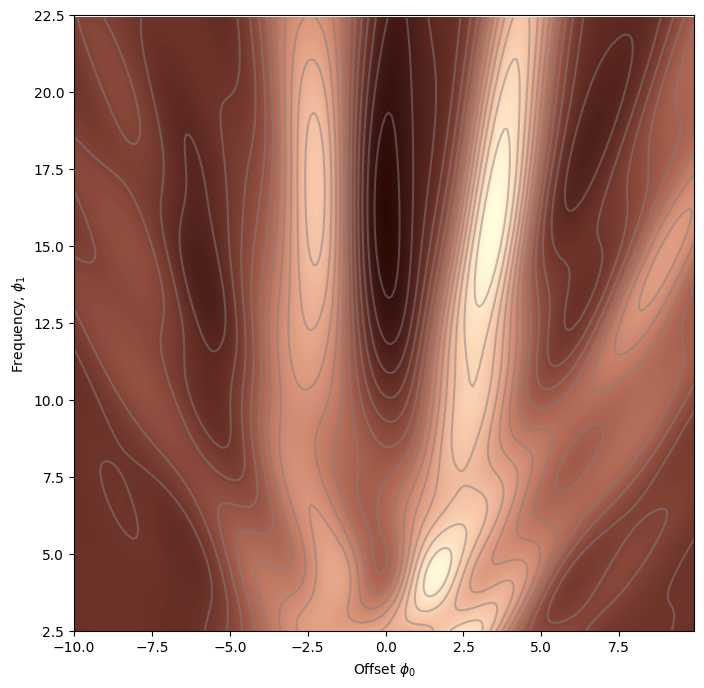

In [2]:
draw_loss_function(compute_loss, data, model, my_colormap)

Now let's compute the gradient vector for a given set of parameters:

\begin{equation}
\frac{\partial L}{\partial \boldsymbol\phi} = \begin{bmatrix}\frac{\partial L}{\partial \phi_0} \\\frac{\partial L}{\partial \phi_1} \end{bmatrix}.
\end{equation}

In [17]:
# These came from writing out the expression for the sum of squares loss and taking the
# derivative with respect to phi0 and phi1. It was a lot of hassle to get it right!
def gabor_deriv_phi0(data_x,data_y,phi0, phi1):
    x = 0.06 * phi1 * data_x + phi0
    y = data_y
    cos_component = np.cos(x)
    sin_component = np.sin(x)
    gauss_component = np.exp(-0.5 * x *x / 16)
    deriv = cos_component * gauss_component - sin_component * gauss_component * x / 16
    deriv = 2* deriv * (sin_component * gauss_component - y)
    return np.sum(deriv)

def gabor_deriv_phi1(data_x, data_y,phi0, phi1):
    x = 0.06 * phi1 * data_x + phi0
    y = data_y
    cos_component = np.cos(x)
    sin_component = np.sin(x)
    gauss_component = np.exp(-0.5 * x *x / 16)
    deriv = 0.06 * data_x * cos_component * gauss_component - 0.06 * data_x*sin_component * gauss_component * x / 16
    deriv = 2*deriv * (sin_component * gauss_component - y)
    return np.sum(deriv)

def compute_gradient(data_x, data_y, phi):
    dl_dphi0 = gabor_deriv_phi0(data_x, data_y, phi[0],phi[1])
    dl_dphi1 = gabor_deriv_phi1(data_x, data_y, phi[0],phi[1])
    # Return the gradient
    return np.array([[dl_dphi0],[dl_dphi1]])

Now we are ready to find the minimum.  For simplicity, we'll just use regular (non-stochastic) gradient descent with a fixed learning rate.

In [14]:
def gradient_descent_step(phi, data,  model):
  # Step 1:  Compute the gradient
  gradient = compute_gradient(data[0,:],data[1,:], phi)
  # Step 2:  Update the parameters -- note we want to search in the negative (downhill direction)
  alpha = 0.1
  phi = phi - alpha * gradient
  return phi

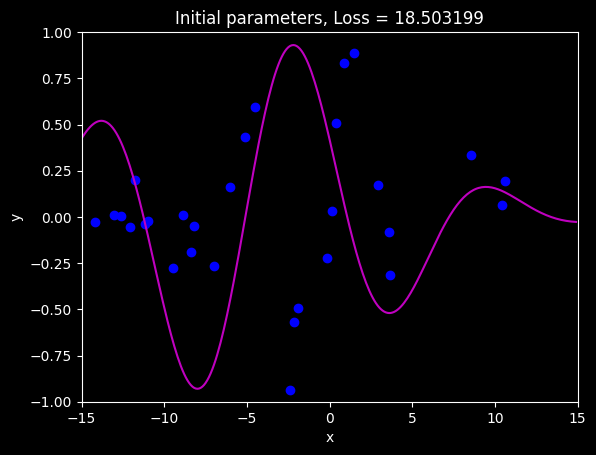

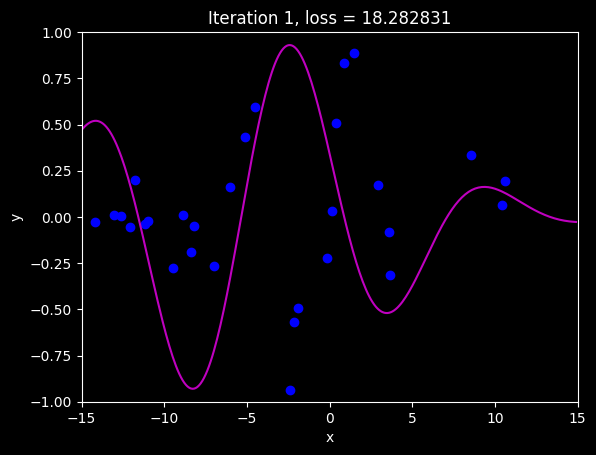

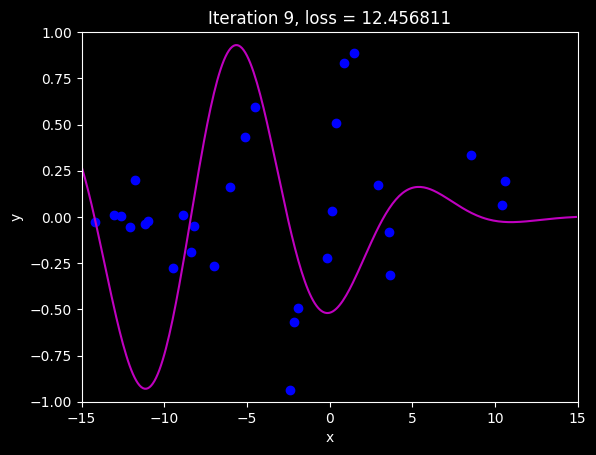

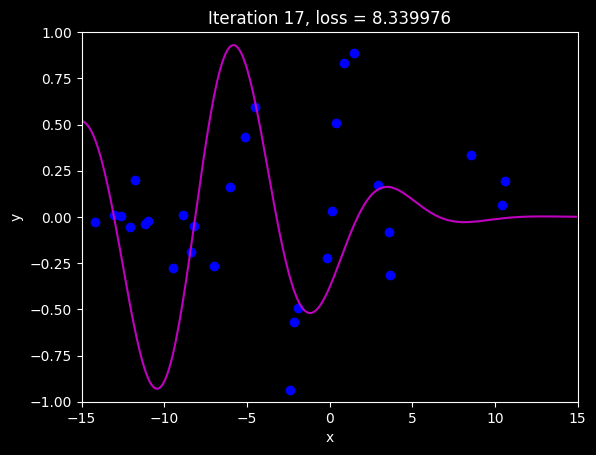

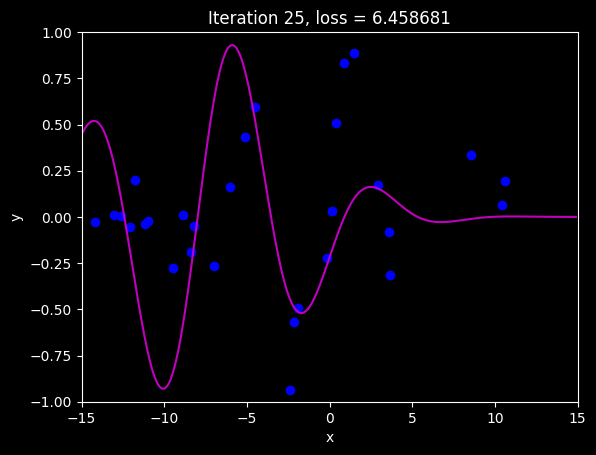

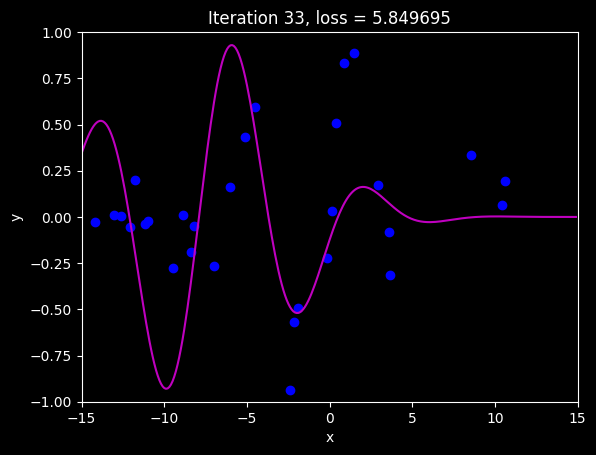

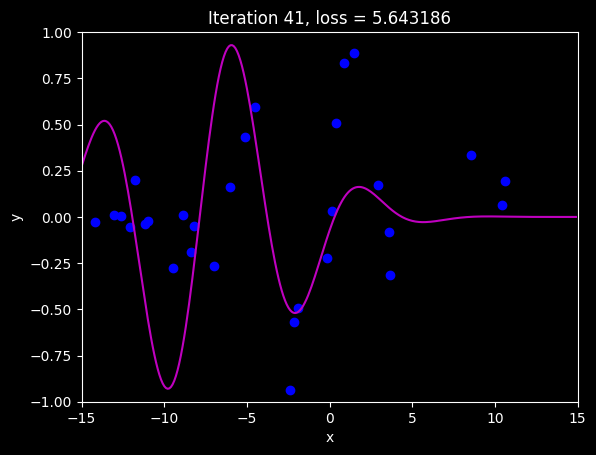

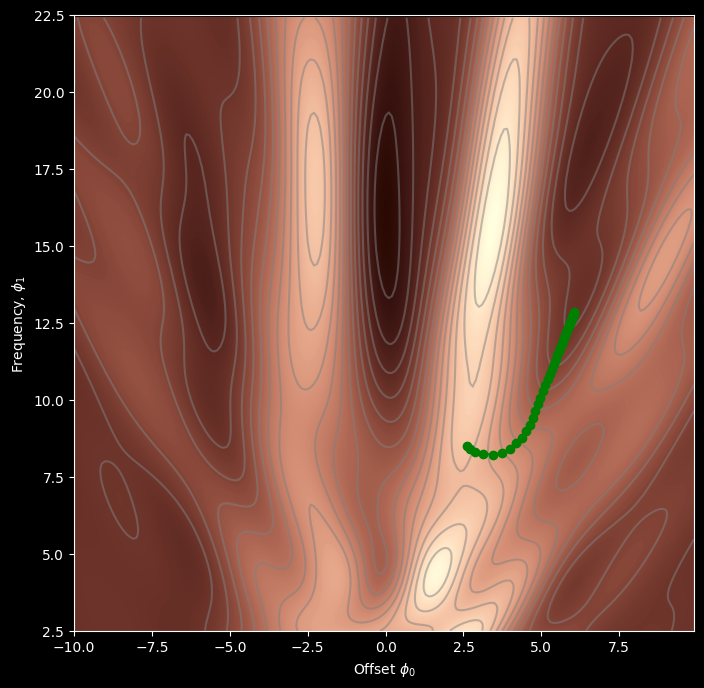

In [15]:
# Initialize the parameters
n_steps = 41
phi_all = np.zeros((2,n_steps+1))
phi_all[0,0] = 2.6
phi_all[1,0] = 8.5

# Measure loss and draw initial model
loss =  compute_loss(data[0,:], data[1,:], model, phi_all[:,0:1])
draw_model(data,model,phi_all[:,0:1], "Initial parameters, Loss = %f"%(loss))

for c_step in range (n_steps):
  # Do gradient descent step
  phi_all[:,c_step+1:c_step+2] = gradient_descent_step(phi_all[:,c_step:c_step+1],data, model)
  # Measure loss and draw model every 8th step
  if c_step % 8 == 0:
    loss =  compute_loss(data[0,:], data[1,:], model, phi_all[:,c_step+1:c_step+2])
    draw_model(data,model,phi_all[:,c_step+1], "Iteration %d, loss = %f"%(c_step+1,loss))

draw_loss_function(compute_loss, data, model, my_colormap, phi_all)


Unfortunately, when we start from this position, the solution descends to a local minimum and the final model doesn't fit well.<br><br>

But what if we had some weak knowledge that the solution was in the vicinity of $\phi_0=0.0$, $\phi_{1} = 12.5$ (the center of the plot)?

Let's add a term to the loss function that penalizes solutions that deviate from this point.  

\begin{equation}
L'[\boldsymbol\phi] = L[\boldsymbol\phi]+ \lambda\cdot \Bigl(\phi_{0}^2+(\phi_1-12.5)^2\Bigr)
\end{equation}

where $\lambda$ controls the relative importance of the original loss and the regularization term

In [12]:
# Computes the regularization term
def compute_reg_term(phi0,phi1):
  reg_term = phi0*phi0 + phi1*phi1

  return reg_term ;

# Define the loss function
# Note I called the weighting lambda_ to avoid confusing it with python lambda functions
def compute_loss2(data_x, data_y, model, phi, lambda_):
  pred_y = model(phi, data_x)
  loss = np.sum((pred_y-data_y)*(pred_y-data_y))
  # Add the new term to the loss
  loss = loss + lambda_ * compute_reg_term(phi[0],phi[1])

  return loss

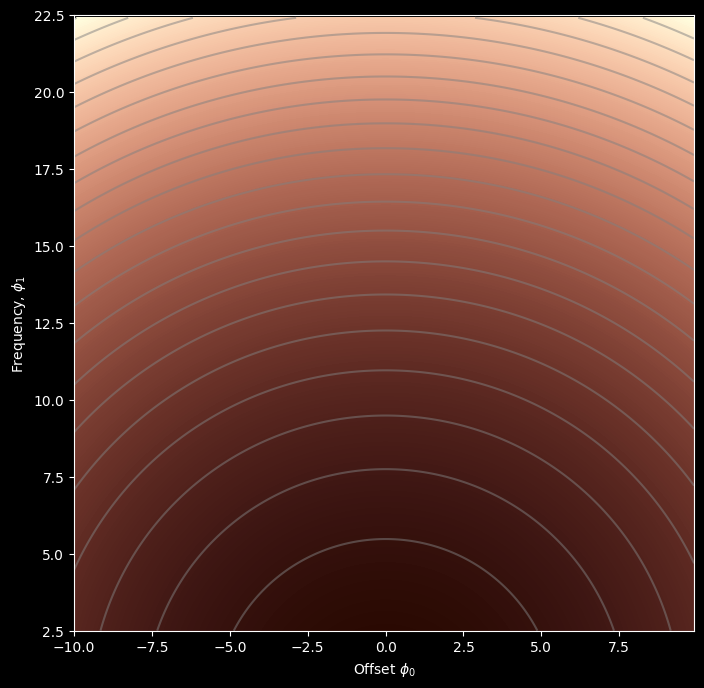

In [13]:
# Code to draw the regularization function
def draw_reg_function():

  # Make grid of offset/frequency values to plot
  offsets_mesh, freqs_mesh = np.meshgrid(np.arange(-10,10.0,0.1), np.arange(2.5,22.5,0.1))
  loss_mesh = np.zeros_like(freqs_mesh)
  # Compute loss for every set of parameters
  for idslope, slope in np.ndenumerate(freqs_mesh):
     loss_mesh[idslope] = compute_reg_term(offsets_mesh[idslope], slope)

  fig,ax = plt.subplots()
  fig.set_size_inches(8,8)
  ax.contourf(offsets_mesh,freqs_mesh,loss_mesh,256,cmap=my_colormap)
  ax.contour(offsets_mesh,freqs_mesh,loss_mesh,20,colors=['#80808080'])
  ax.set_ylim([2.5,22.5])
  ax.set_xlabel('Offset $\phi_{0}$'); ax.set_ylabel('Frequency, $\phi_{1}$')
  plt.show()

# Draw the regularization function.  It should look similar to figure 9.1b
draw_reg_function()

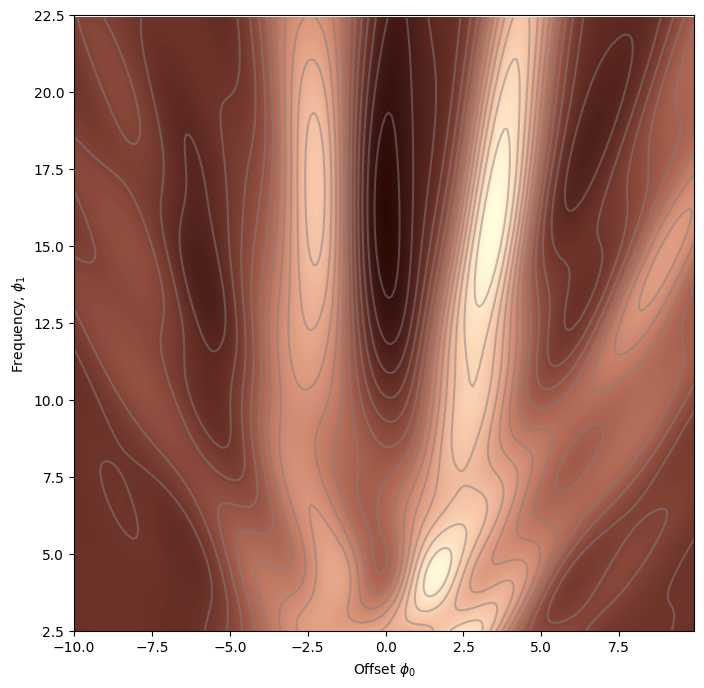

In [8]:
# Code to draw loss function with regularization
def draw_loss_function_reg(data,  model, lambda_, my_colormap, phi_iters = None):

  # Make grid of offset/frequency values to plot
  offsets_mesh, freqs_mesh = np.meshgrid(np.arange(-10,10.0,0.1), np.arange(2.5,22.5,0.1))
  loss_mesh = np.zeros_like(freqs_mesh)
  # Compute loss for every set of parameters
  for idslope, slope in np.ndenumerate(freqs_mesh):
     loss_mesh[idslope] = compute_loss2(data[0,:], data[1,:], model, np.array([[offsets_mesh[idslope]], [slope]]), lambda_)

  fig,ax = plt.subplots()
  fig.set_size_inches(8,8)
  ax.contourf(offsets_mesh,freqs_mesh,loss_mesh,256,cmap=my_colormap)
  ax.contour(offsets_mesh,freqs_mesh,loss_mesh,20,colors=['#80808080'])
  if phi_iters is not None:
    ax.plot(phi_iters[0,:], phi_iters[1,:],'go-')
  ax.set_ylim([2.5,22.5])
  ax.set_xlabel('Offset $\phi_{0}$'); ax.set_ylabel('Frequency, $\phi_{1}$')
  plt.show()

# This should look something like figure 9.1c
draw_loss_function_reg(data, model, 0.2, my_colormap)

Now we'll compute the derivatives $\frac{\partial L'}{\partial\phi_0}$ and $\frac{\partial L'}{\partial\phi_1}$ of the regularized loss function:

\begin{equation}
L'[\boldsymbol\phi] = L[\boldsymbol\phi]+ \lambda\cdot \Bigl(\phi_{0}^2+(\phi_1-12.5)^2\Bigr)
\end{equation}

so that we can perform gradient descent.

In [9]:
def dldphi0(phi, lambda_):
  deriv = lambda_ * phi[0]
  return deriv

def dldphi1(phi, lambda_):
  deriv = lambda_ * phi[1]


  return deriv


def compute_gradient2(data_x, data_y, phi, lambda_):
    dl_dphi0 = gabor_deriv_phi0(data_x, data_y, phi[0],phi[1])+dldphi0(np.squeeze(phi), lambda_)
    dl_dphi1 = gabor_deriv_phi1(data_x, data_y, phi[0],phi[1])+dldphi1(np.squeeze(phi), lambda_)
    # Return the gradient
    return np.array([[dl_dphi0],[dl_dphi1]])

def gradient_descent_step2(phi, lambda_, data,  model):
  # Step 1:  Compute the gradient
  gradient = compute_gradient2(data[0,:],data[1,:], phi, lambda_)
  # Step 2:  Update the parameters -- note we want to search in the negative (downhill direction)
  alpha = 0.1
  phi = phi - alpha * gradient
  return phi

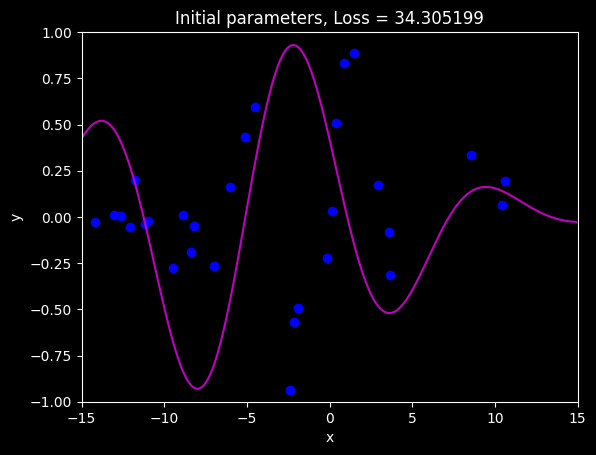

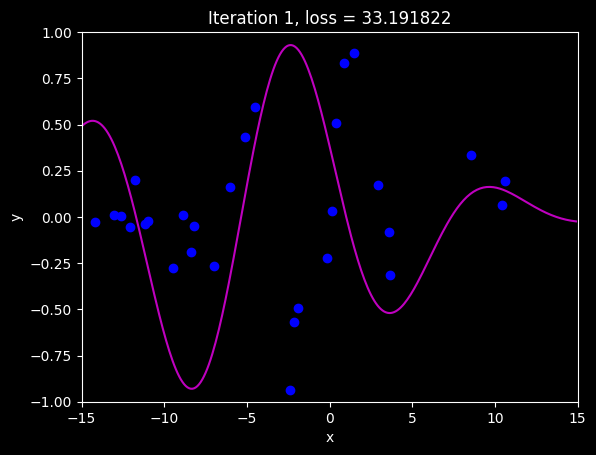

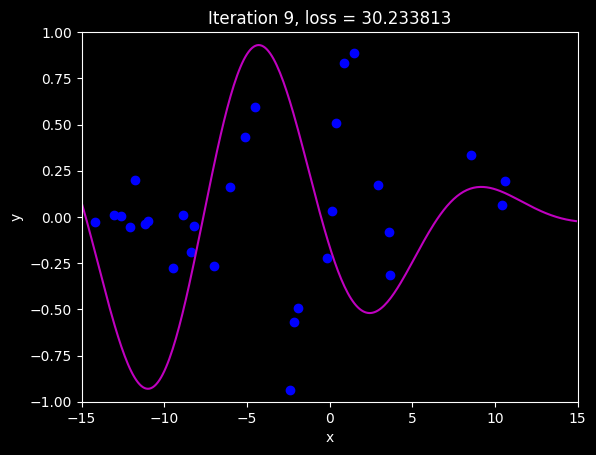

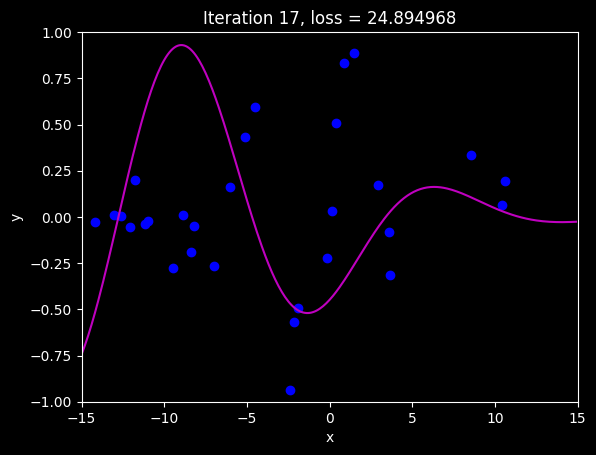

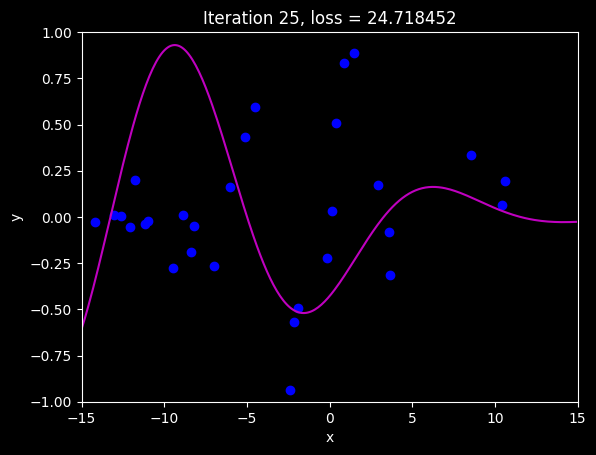

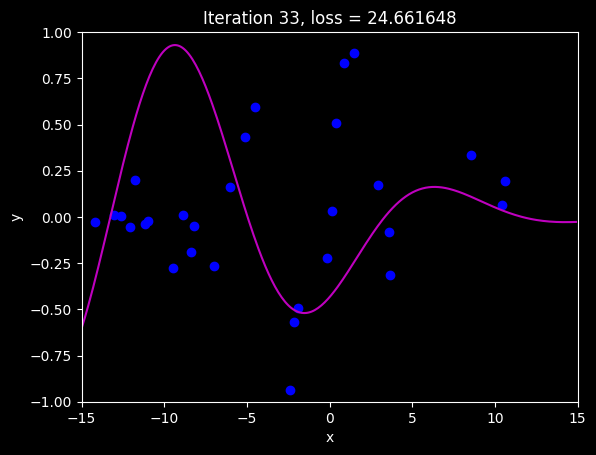

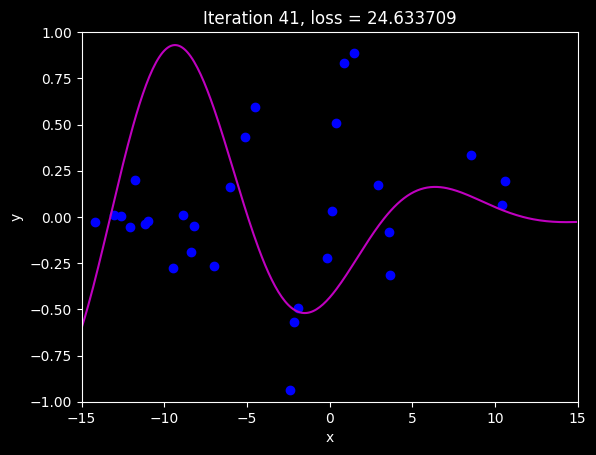

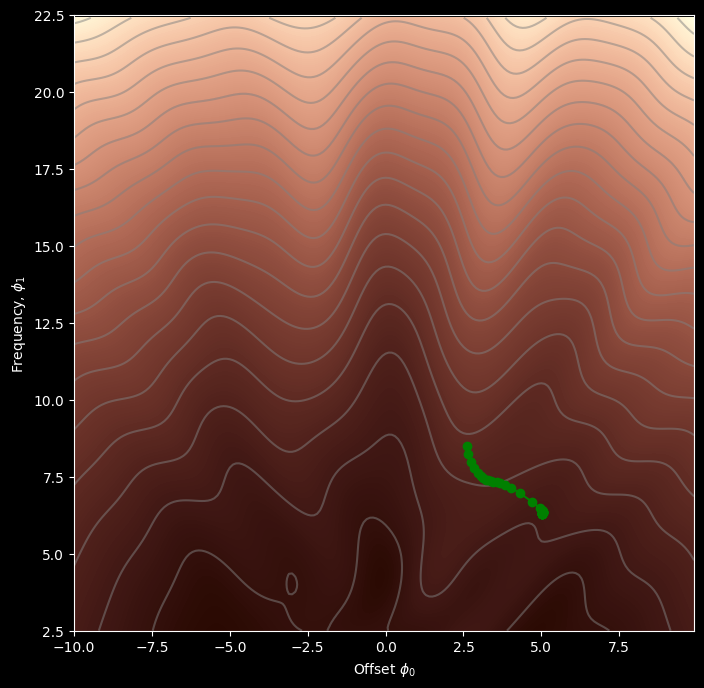

In [18]:
# Finally, let's run gradient descent and draw the result
# Initialize the parameters
n_steps = 41
phi_all = np.zeros((2,n_steps+1))
phi_all[0,0] = 2.6
phi_all[1,0] = 8.5
lambda_ = 0.2

# Measure loss and draw initial model
loss =  compute_loss2(data[0,:], data[1,:], model, phi_all[:,0:1], lambda_)
draw_model(data,model,phi_all[:,0:1], "Initial parameters, Loss = %f"%(loss))

for c_step in range (n_steps):
  # Do gradient descent step
  phi_all[:,c_step+1:c_step+2] = gradient_descent_step2(phi_all[:,c_step:c_step+1],lambda_, data, model)
  # Measure loss and draw model every 8th step
  if c_step % 8 == 0:
    loss =  compute_loss2(data[0,:], data[1,:], model, phi_all[:,c_step+1:c_step+2], lambda_)
    draw_model(data,model,phi_all[:,c_step+1], "Iteration %d, loss = %f"%(c_step+1,loss))

draw_loss_function_reg(data, model, lambda_, my_colormap, phi_all)

You should see that the gradient descent algorithm now finds the correct minimum.  By applying a tiny bit of domain knowledge (the parameter phi0 tends to be near zero and the parameter phi1 tends to be near 12.5), we get a better solution.  However, the cost is that this solution is slightly biased towards this prior knowledge.

In Pytorch, L2 regularization is implemented using the weight_decay parameter in the optimizer. For example:

```python
optimizer = torch.optim.SGD(
    model.parameters(),
    lr=0.01,
    weight_decay=1e-4,
)
```

For SGD, this corresponds to minimizing:
$$
L_{\text{total}} = L_{\text{task}} + \frac{\lambda}{2}\sum_p \|p\|_2^2
$$

Here, weight_decay is \(\lambda\). Larger values penalize large weights more strongly. PyTorch SGD documentation
You can also set weight_decay with Adam, where its default behavior applies an L2 penalty. AdamW instead applies decoupled weight decay, which behaves differently from adding L2 to the loss. Adam documentation
To add L2 explicitly:

In [ ]:
# Keep optimizer weight_decay=0 to avoid applying it twice.
loss = criterion(model(inputs), targets)
l2_penalty = sum(p.square().sum() for p in model.parameters())
loss = loss + (1e-4 / 2) * l2_penalty

optimizer.zero_grad()
loss.backward()
optimizer.step()

These examples penalize all model parameters, including biases.
If you want to exclude biases from L2 regularization, you can filter them out when computing the penalty:

```python
l2_penalty = sum(p.square().sum() for n, p in model.named_parameters() if 'bias' not in n)
```

## Early stopping

Early stopping refers to stopping the training procedure before it has fully converged.

This can reduce overfitting if the model has already captured the coarse shape of the underlying function but has not yet had time to overfit to the noise.

One way of thinking about this is that since the weights are initialized to small values they simply don’t have time to become large, so early stopping has a similar effect to explicit L2 regularization. 

A different view is that early stopping reduces the effective model complexity. 

Hence, we move back down the bias/variance trade-off curve from the critical region, and performance improves.

Early stopping has a single hyperparameter, the number of steps after which learning is terminated. 

As usual, this is chosen empirically using a validation set.

However, for early stopping, the hyperparameter can be selected without the need to train multiple models. 

The model is trained once, the performance on the validation set is monitored every T iterations, and the associated parameters are stored. 

The stored parameters where the validation performance was best are selected.

<img src="assets/Chap09/RegEarly.svg" width="100%" style="filter:invert(1)">

Early stopping. a) Simplified shallow network model with 14 linear
regions is initialized randomly (cyan curve) and trained with SGD
using a batch size of five and a learning rate of 0.05. b–d) As training proceeds,
the function first captures the coarse structure of the true function (black curve)
before e–f) overfitting to the noisy training data (orange points). Although the
training loss continues to decrease throughout this process, the learned models in
panels (c) and (d) are closest to the true underlying function. They will generalize
better on average to test data than those in panels (e) or (f).



In [ ]:
from copy import deepcopy

best_loss = float("inf")
best_weights = None
patience = 5
stale_epochs = 0

for epoch in range(100):
    train_one_epoch(model, train_loader, optimizer)
    val_loss = evaluate(model, val_loader)  # scalar validation loss

    if val_loss < best_loss - 1e-4:
        best_loss = val_loss
        best_weights = deepcopy(model.state_dict())
        stale_epochs = 0
    else:
        stale_epochs += 1
        if stale_epochs >= patience:
            break

# Restore the best model
if best_weights is not None:
    model.load_state_dict(best_weights)

Here, patience=5 allows five epochs without meaningful improvement. Your evaluation function should use model.eval() and torch.no_grad(); training should switch back to model.train().